In [1]:
import argparse
import json
import logging
import os
import time
import math
from collections import defaultdict, Counter
from typing import Dict, List, Optional, Tuple, Set
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoTokenizer, 
    AutoModelForCausalLM,
    set_seed
)
from datasets import load_dataset
import matplotlib.pyplot as plt
from tqdm import tqdm
import pickle

from src.activation_capture import ACTIVATION_CAPTURE

# Setup logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class ContextualSparsityAnalyzer:
    """Analyzer for measuring contextual sparsity patterns in LLaMA models."""
    
    def __init__(self, model, tokenizer, device):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device

        self.capture = ACTIVATION_CAPTURE[model.config.model_type]()
        self.capture.register_hooks(model)
        self.num_layers = len(self.capture.get_layers(model))

        self.reset_buffers()
        
    def reset_buffers(self):
        self.mlp_sparsity = {}
        self.mlp_sparsity['gate'] = defaultdict(list)
        self.mlp_sparsity['up'] = defaultdict(list)
        self.num_seqs = 0

    def process_batch(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> Dict:      
        batch_size = input_ids.size(0)

        # Clear previous captures and GPU cache
        self.capture.clear_captures()
        if self.device.type == "cuda":
            torch.cuda.empty_cache()
        
        # Forward pass
        with torch.no_grad():
            _ = self.model(input_ids=input_ids, attention_mask=attention_mask)

        # Compute sparsity
        for layer_idx in range(self.num_layers):
            if layer_idx in self.capture.hidden_states:
                sparsity_masks_gate = (self.capture.get_gate_activations(layer_idx) <= 0)
                sparsity_masks_up = (self.capture.get_mlp_activations(layer_idx) <= 0)

                # Naive sparsity computation
                self.mlp_sparsity['gate'][layer_idx].append(sparsity_masks_gate.float().mean().item())
                self.mlp_sparsity['up'][layer_idx].append(sparsity_masks_up.float().mean().item())

                # Level of sparsity after union over batch dim
                #union_sparsity_mask = sparsity_masks.any(dim=0)
                #self.union_sparsity[batch_size][layer_idx].append(union_sparsity_mask.float().mean().item())

                # TODO: Add HNSW sparsity computation for both attn heads and mlp neurons
                # TODO: Compute union sparsity over multiple different batch sizes

        # Clear GPU tensors from capture to free memory
        self.capture.clear_captures()
        if self.device.type == "cuda":
            torch.cuda.empty_cache()

        self.num_seqs += batch_size
        

def analyze_sparsity(args, model_name, device):
    # Load model and tokenizer
    logger.info(f"Loading model: {model_name}")
    tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=torch.float16 if device.type == "cuda" else torch.float32,
        device_map="auto" if device.type == "cuda" else None,
        trust_remote_code=True
    )
    
    if device.type != "cuda":
        model = model.to(device)
    
    # Load C4 dataset
    dataset = C4Dataset(tokenizer, args.max_length, args.num_samples)
    dataloader = DataLoader(dataset, batch_size=args.batch_size, shuffle=False)

    analyzer = ContextualSparsityAnalyzer(model, tokenizer, device)
    try:
        # Process dataset
        logger.info("Starting contextual sparsity analysis...")
        
        for batch_idx, batch in enumerate(tqdm(dataloader, desc="Analyzing sequences")):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            analyzer.process_batch(input_ids, attention_mask)

            # Log progress
            if (batch_idx + 1) % 100 == 0:
                logger.info(f"Processed {batch_idx + 1}/{len(dataloader)} sequences")

        for key, layer_sparsities in analyzer.mlp_sparsity.items():
            analyzer.mlp_sparsity[key] = [sum(layer_sparsities[layer_idx]) / len(layer_sparsities[layer_idx]) for layer_idx in range(len(layer_sparsities))]
            for layer_idx in range(len(layer_sparsities)):
                analyzer.mlp_sparsity[key][layer_idx] = sum(layer_sparsities[layer_idx]) / len(layer_sparsities[layer_idx])

        # TODO: Print/save logs and sparsity statistics
    finally:
        analyzer.capture.remove_hooks()
    return analyzer.mlp_sparsity

        
def plot_sparsities(args, device):
    outs = defaultdict(dict)
    for model in args.models:
        model_name = model.split("/")[1].capitalize()
        model_sparsities = analyze_sparsity(args, model, device)
        for k, v in model_sparsities.items():
            outs[k][model_name] = v
    
    for k, outs_k in outs.items():
        plt.figure(figsize=(10, 6))
        for model_name, model_sparsities in outs_k.items():
            plt.plot(range(len(model_sparsities)), model_sparsities, label=model_name)
        plt.xlabel('Layer Index')
        plt.ylabel(f"% of Neurons Inactive")
        plt.title(f"{k.capitalize()} Sparsity By Layer")
        plt.legend()
        plt.minorticks_on()

    if args.save_plots:
        plt.savefig(os.path.join(args.output_dir, 'sparsity_analysis.png'), dpi=300, bbox_inches='tight')

class C4Dataset(Dataset):
    """C4 dataset for contextual sparsity analysis."""
    
    def __init__(self, tokenizer, max_length: int = 512, num_samples: int = 1000):
        self.tokenizer = tokenizer
        self.max_length = max_length
        
        # Load C4 dataset
        logger.info("Loading C4 dataset...")
        dataset = load_dataset("allenai/c4", "realnewslike", split="train", streaming=True)
        
        # Process samples
        self.samples = []
        for i, sample in enumerate(dataset):
            if i >= num_samples:
                break
                
            text = sample['text']
            if len(text.strip()) > 50:  # Filter out very short texts
                encoding = tokenizer(
                    text,
                    truncation=True,
                    padding='max_length',
                    max_length=max_length,
                    return_tensors='pt'
                )
                
                if encoding['input_ids'].shape[1] > 10:  # Ensure minimum sequence length
                    self.samples.append({
                        'input_ids': encoding['input_ids'].squeeze(),
                        'attention_mask': encoding['attention_mask'].squeeze(),
                        'text': text[:200] + "..." if len(text) > 200 else text
                    })
        
        logger.info(f"Loaded {len(self.samples)} C4 samples")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        return self.samples[idx]

Configuring for 4 CPU threads


In [2]:
args = argparse.Namespace()
args.num_samples=2048
args.batch_size=8
args.device="auto"
args.max_length=512

if args.device == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    device = torch.device(args.device)

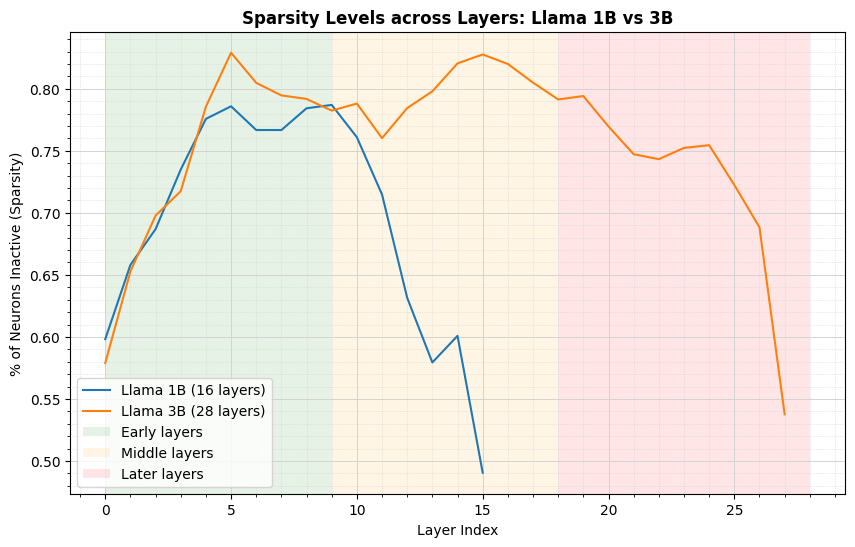

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(range(len(out_1b['gate'])), out_1b['gate'], label="Llama 1B (16 layers)")
plt.plot(range(len(out_3b['gate'])), out_3b['gate'], label="Llama 3B (28 layers)")
plt.xlabel('Layer Index')
plt.ylabel(f"% of Neurons Inactive (Sparsity)")
plt.title(f"Sparsity Levels across Layers: Llama 1B vs 3B", fontweight='bold')
plt.minorticks_on()
plt.grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
plt.grid(which='major', linestyle='-', linewidth=0.7, color='lightgray')
plt.axvspan(0, 9, facecolor='green', alpha=0.1, label="Early layers")
plt.axvspan(9, 18, facecolor='orange', alpha=0.1, label="Middle layers")
plt.axvspan(18, 28, facecolor='red', alpha=0.1, label="Later layers")
plt.legend()


In [40]:
plt.savefig("llama_plot.png")

<Figure size 640x480 with 0 Axes>

In [ ]:
out_3b = analyze_sparsity(args, "meta-llama/Llama-3.2-3B-Instruct", device)

In [3]:
models = {
    "DeepSeek-Qwen-1.5B": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "Gemma-3N-E2B": "google/gemma-3n-E2B",
    "Llama-3B": "meta-llama/Llama-3.2-3B-Instruct",
    "Llama-1B": "meta-llama/Llama-3.2-1B-Instruct",
}

In [3]:
out_gemma = analyze_sparsity(args, "google/gemma-3n-E2B", device)

INFO:__main__:Loading model: google/gemma-3n-E2B
INFO:accelerate.utils.modeling:We will use 90% of the memory on device 0 for storing the model, and 10% for the buffer to avoid OOM. You can set `max_memory` in to a higher value to use more memory (at your own risk).


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

INFO:__main__:Loading C4 dataset...


Resolving data files:   0%|          | 0/1024 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/512 [00:00<?, ?it/s]

INFO:__main__:Loaded 2048 C4 samples
INFO:__main__:Starting contextual sparsity analysis...
Analyzing sequences:   0%|                                                                      | 0/256 [00:01<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 64.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 24.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 14.36 GiB is allocated by PyTorch, and 54.48 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [8]:
out = {}
for model_name, model_tag in models.items():
    outs_model = analyze_sparsity(args, model_tag, device)
    out[model_name] = outs_model['gate']
    del outs_model

INFO:__main__:Loading model: meta-llama/Llama-3.2-3B-Instruct
INFO:accelerate.utils.modeling:We will use 90% of the memory on device 0 for storing the model, and 10% for the buffer to avoid OOM. You can set `max_memory` in to a higher value to use more memory (at your own risk).


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

INFO:__main__:Loading C4 dataset...


Resolving data files:   0%|          | 0/1024 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/512 [00:00<?, ?it/s]

...

tokenizer.model:   0%|          | 0.00/4.70M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/769 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.92k [00:00<?, ?B/s]

ValueError: The checkpoint you are trying to load has model type `gemma3n` but Transformers does not recognize this architecture. This could be because of an issue with the checkpoint, or because your version of Transformers is out of date.

You can update Transformers with the command `pip install --upgrade transformers`. If this does not work, and the checkpoint is very new, then there may not be a release version that supports this model yet. In this case, you can get the most up-to-date code by installing Transformers from source with the command `pip install git+https://github.com/huggingface/transformers.git`

In [ ]:
out.keys()